# Consumer Credit Risk Model
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/aldo02032004/credit-risk-model/blob/main/credit_risk_model.ipynb)

**Credit risk portfolio · Python · PD model, validation, expected loss, Vasicek Monte Carlo · public data**

**Summary.** This notebook builds a probability of default (PD) model on 150,000 real borrowers, validates it the way a bank does, turns it into a score cutoff, and estimates the portfolio's expected loss, VaR and stressed loss.

**Questions answered**
1. How well does the PD model rank and calibrate risk, and is it stable?
2. Which score cutoff makes lending profitable, and what does it change?
3. What is the expected loss, and how large can a bad year's loss be?

| Section | Content |
|---|---|
| 0 | Assumptions and setup |
| 1 | Data |
| 2 | PD model and validation |
| 3 | Score and cutoff |
| 4 | Expected loss, Monte Carlo and stress test |
| 5 | **Results: all key tables and charts** |

Sections 0-4 only compute. To see the results, go straight to **section 5**. This is a learning project, not a model of any real lender.

## 0. Assumptions and setup

Only four assumptions, all in `P`. Everything else comes from the data.

| Assumption | Value | Why |
|---|---|---|
| LGD | 45% | Basel foundation IRB value for unsecured senior exposure |
| EAD | Equal for every loan | The dataset has no loan amounts, so losses are shown as % of the portfolio |
| Asset correlation ρ | 15% | Upper end of the Basel range for retail loans (3%-16%) |
| Net margin | 8% a year | After funding and operating cost, used for the break-even cutoff |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss
from sklearn.calibration import calibration_curve

sns.set_theme(style="whitegrid", font_scale=0.9)
pd.options.display.float_format = "{:,.3f}".format

P = dict(
    lgd=0.45, rho=0.15, margin=0.08,      # asumsi (lihat tabel di atas)
    pdo=20, base_score=600, base_odds=50, # skala skor: 600 poin = odds baik:buruk 50:1, +20 poin = odds 2×
    n_sims=10_000, conf=0.99, test_size=0.3, seed=42,
)

# --- Helper (pola sama dengan proyek LNG) ---
pct = lambda x: f"{x:.2%}".replace(".", ",")
status = lambda x, hijau, kuning: str(np.select([x <= hijau, x <= kuning], ["HIJAU", "KUNING"], "MERAH"))
warna = {"HIJAU": "#a5d6a7", "KUNING": "#ffe082", "MERAH": "#ef9a9a"}

## 1. Data

[Give Me Some Credit](https://www.openml.org/d/46929): 150,000 borrowers, 10 features (credit utilization, age, past-due history, debt ratio, income, number of loans, dependents). The target is serious delinquency (90+ days past due) within 2 years. Downloaded from OpenML and cached by scikit-learn, no account needed.

In [2]:
gm = fetch_openml(data_id=46929, as_frame=True).frame
y = (gm.pop("FinancialDistressNextTwoYears") == "Yes").astype(int)
print(f"{len(gm):,} peminjam, {gm.shape[1]} fitur, default rate 2 tahun {pct(y.mean())}")
print("Data kosong per kolom:"); display(gm.isna().mean()[lambda s: s > 0].to_frame("porsi kosong"))

150,000 peminjam, 10 fitur, default rate 2 tahun 6,68%
Data kosong per kolom:


,porsi kosong
MonthlyIncome,0.198
NumberOfDependents,0.026


## 2. PD model and validation

- **Split:** 70% development, 30% validation, stratified on the target.
- **Champion: logistic regression.** Outliers capped at the development 99th percentile, missing values imputed with the median plus a missing flag, `log1p` transform, standardization. Its coefficients can be read and challenged, which is why banks still prefer it.
- **Challenger: gradient boosting** on raw features. If it is only slightly better, the readable model stays.
- **Metrics:** AUC and Gini (ranking), KS (separation of good and bad borrowers), Brier score and calibration curve (is the PD level right), PSI (is the score distribution stable).

In [3]:
X_dev, X_val, y_dev, y_val = train_test_split(gm, y, test_size=P["test_size"], stratify=y, random_state=P["seed"])
cap = X_dev.quantile(0.99)                                          # batas outlier dari data development saja
logit = make_pipeline(FunctionTransformer(lambda X: X.clip(lower=0, upper=cap, axis=1)),
                      SimpleImputer(strategy="median", add_indicator=True),
                      FunctionTransformer(np.log1p), StandardScaler(), LogisticRegression(max_iter=1000))
gbm = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=500, early_stopping=True, random_state=P["seed"])
models = {"Logistik": logit.fit(X_dev, y_dev), "Gradient boosting": gbm.fit(X_dev, y_dev)}
p_dev = {k: m.predict_proba(X_dev)[:, 1] for k, m in models.items()}
p_val = {k: m.predict_proba(X_val)[:, 1] for k, m in models.items()}

def validasi(y, p):
    fpr, tpr, _ = roc_curve(y, p)
    auc = roc_auc_score(y, p)
    return pd.Series({"AUC": auc, "Gini": 2 * auc - 1, "KS": (tpr - fpr).max(), "Brier": brier_score_loss(y, p),
                      "PD rata-rata": p.mean(), "Default rate aktual": y.mean()})

def psi(a, b, bins=10):                                             # a = acuan (development), b = pembanding
    edges = np.unique(np.quantile(a, np.linspace(0, 1, bins + 1))); edges[[0, -1]] = -np.inf, np.inf
    pa, pb = (np.clip(np.histogram(x, edges)[0] / len(x), 1e-6, None) for x in (a, b))
    return ((pa - pb) * np.log(pa / pb)).sum()

val = pd.DataFrame({k: validasi(y_val, p) for k, p in p_val.items()}).T
val["AUC dev"] = [roc_auc_score(y_dev, p_dev[k]) for k in val.index]
val["PSI dev→val"] = [psi(p_dev[k], p_val[k]) for k in val.index]
coef = pd.Series(logit[-1].coef_[0], index=logit[1].get_feature_names_out(X_dev.columns)).sort_values(key=abs, ascending=False)

# Cek logika: model jauh lebih baik dari acak, PSI dua sampel identik = 0
assert (val.AUC > 0.75).all() and psi(p_dev["Logistik"], p_dev["Logistik"]) < 1e-9

## 3. Score and cutoff

- **12-month PD:** the target covers 2 years, so PD₁₂ = 1 − (1 − PD₂)^½.
- **Score:** points = 600 + 20/ln 2 × ln(odds / 50). 600 points means good:bad odds of 50:1, and every 20 points doubles the odds.
- **Break-even cutoff:** a loan pays off when the margin on good loans covers the loss on bad ones, margin × (1 − PD) ≥ PD × LGD. So the break-even PD₁₂ is margin / (margin + LGD) = 8% / 53% ≈ 15%.
- The cutoff is tested on the validation sample against **actual** outcomes, so its effect is measured, not assumed.

In [4]:
port = pd.DataFrame({"pd2": p_val["Logistik"], "default": y_val.to_numpy()})
port["pd12"] = 1 - (1 - port.pd2) ** 0.5
factor = P["pdo"] / np.log(2)
skor = lambda p2: P["base_score"] + factor * np.log((1 - p2) / p2 / P["base_odds"])
port["skor"] = skor(port.pd2)

pd_be = P["margin"] / (P["margin"] + P["lgd"])                      # PD12 break-even
cutoff = skor(1 - (1 - pd_be) ** 2)                                 # PD12 → PD 2 tahun → poin
port["lolos"] = port.skor >= cutoff

# Default rate aktual per desil skor: bukti model mengurutkan risiko dengan benar
port["desil"] = pd.qcut(port.skor, 10, labels=range(1, 11))
band = port.groupby("desil", observed=True).agg(skor_min=("skor", "min"), skor_max=("skor", "max"),
                                                pd_prediksi=("pd2", "mean"), default_aktual=("default", "mean"))
assert skor(0.01) > skor(0.2) and band.default_aktual.is_monotonic_decreasing

## 4. Expected loss, Monte Carlo and stress test

**Expected loss** per loan is EL = PD₁₂ × LGD × EAD. With equal EAD, the portfolio EL rate is the average PD₁₂ × LGD.

**Vasicek one-factor model.** A borrower defaults when √ρ·Z + √(1−ρ)·ε < Φ⁻¹(PD), where Z is one economy-wide factor and ε is the borrower's own risk. Given Z, the default rate of a large portfolio is

PD(Z) = Φ( (Φ⁻¹(PD) − √ρ·Z) / √(1−ρ) )

- **Monte Carlo:** 10,000 draws of Z ~ N(0, 1), the same set-up as the LNG project. Loans are grouped into 50 PD buckets so each scenario is a small matrix product.
- **Check:** in a one-factor model the 99% loss is exactly the loss at Z = Φ⁻¹(1%), so the simulated VaR must match that closed form.
- **Stress test:** the loss at fixed bad values of Z: −1 (mild, about 1 year in 6), −2 (severe, 1 in 44) and −3 (extreme, 1 in 740).

In [5]:
def buckets(book):                                                  # ringkas buku jadi 50 bucket PD
    b = book.groupby(pd.qcut(book.pd12, 50, duplicates="drop"), observed=True)
    return b.pd12.mean().to_numpy(), b.size().to_numpy() / len(port)   # PD, porsi eksposur (vs portofolio awal)

def loss(z, book):                                                  # rugi sebagai % portofolio untuk tiap nilai Z
    pd_, w = buckets(book)
    z, r = np.atleast_1d(z)[:, None], P["rho"]
    return norm.cdf((norm.ppf(pd_) - np.sqrt(r) * z) / np.sqrt(1 - r)) @ w * P["lgd"]

def metrics(c):
    var = np.quantile(c, P["conf"])
    return pd.Series({"EL": c.mean(), "Std": c.std(), "VaR 99": var, "CVaR 99": c[c >= var].mean(), "UL = VaR − EL": var - c.mean()})

Z = np.random.default_rng(P["seed"]).standard_normal(P["n_sims"])   # seed sama → skenario sama untuk dua kebijakan
lolos = port[port.lolos]
L, L_cut = loss(Z, port), loss(Z, lolos)
m = pd.DataFrame({"Tanpa cutoff": metrics(L), "Dengan cutoff": metrics(L_cut)})

stres = pd.DataFrame({"Z": [0, -1, -2, -3]}, index=["Median", "Ringan", "Berat", "Ekstrem"])
stres["1 dari N tahun"] = 1 / norm.cdf(stres.Z)
stres["PD12 rata-rata"] = [loss(z, port).item() / P["lgd"] for z in stres.Z]
stres["Rugi tanpa cutoff"] = [loss(z, port).item() for z in stres.Z]
stres["Rugi dengan cutoff"] = [loss(z, lolos).item() for z in stres.Z]
stres["Rugi / EL"] = stres["Rugi tanpa cutoff"] / m.loc["EL", "Tanpa cutoff"]

cut = pd.Series({
    "Approval rate": port.lolos.mean(), "Bad rate aktual, semua": port.default.mean(),
    "Bad rate aktual, lolos": lolos.default.mean(), "Bad rate aktual, ditolak": port[~port.lolos].default.mean(),
    "EL tanpa cutoff": m.loc["EL", "Tanpa cutoff"], "EL dengan cutoff": m.loc["EL", "Dengan cutoff"],
})

# KRI: (nilai, batas hijau, batas kuning); AUC dibalik tanda karena makin tinggi makin baik
kri = pd.DataFrame([
    ("AUC model PD",       val.AUC["Logistik"],  0.75, 0.70, -1),   # batas umum validasi model
    ("PSI skor dev → val", val["PSI dev→val"]["Logistik"], 0.10, 0.25, 1),   # konvensi PSI industri
    ("VaR 99 (% portofolio)", m.loc["VaR 99", "Tanpa cutoff"], 0.04, 0.06, 1),   # risk appetite (asumsi)
], columns=["KRI", "nilai", "hijau", "kuning", "arah"]).set_index("KRI")
kri["status"] = [status(r.arah * r.nilai, r.arah * r.hijau, r.arah * r.kuning) for r in kri.itertuples()]

# Cek: EL simulasi ≈ EL analitik, VaR simulasi ≈ rumus tertutup, cutoff menurunkan EL dan bad rate
assert abs(m.loc["EL", "Tanpa cutoff"] / (port.pd12.mean() * P["lgd"]) - 1) < 0.02
assert abs(m.loc["VaR 99", "Tanpa cutoff"] / loss(norm.ppf(1 - P["conf"]), port).item() - 1) < 0.03
assert cut["Bad rate aktual, lolos"] < cut["Bad rate aktual, semua"] < cut["Bad rate aktual, ditolak"]

## 5. Results

### 5.1 Summary

In [6]:
mt, mc = m["Tanpa cutoff"], m["Dengan cutoff"]
print(f"RINGKASAN RISIKO KREDIT · {len(port):,} pinjaman (sampel validasi)")
print(f"- Model PD : AUC {val.AUC['Logistik']:.3f}, Gini {val.Gini['Logistik']:.3f}, KS {val.KS['Logistik']:.3f}, "
      f"PSI {val['PSI dev→val']['Logistik']:.4f}. Gradient boosting AUC {val.AUC['Gradient boosting']:.3f}")
print(f"- Cutoff   : {cutoff:.0f} poin (PD12 break-even {pct(pd_be)}). Approval {pct(cut['Approval rate'])}, "
      f"bad rate ditolak {pct(cut['Bad rate aktual, ditolak'])} vs lolos {pct(cut['Bad rate aktual, lolos'])}")
print(f"- Kerugian : EL {pct(mt['EL'])} → {pct(mc['EL'])}, VaR 99 {pct(mt['VaR 99'])} → {pct(mc['VaR 99'])} "
      f"dari portofolio (tanpa → dengan cutoff)")
print(f"- Stres    : tahun berat (Z = −2) rugi {pct(stres.loc['Berat', 'Rugi tanpa cutoff'])}, "
      f"{stres.loc['Berat', 'Rugi / EL']:.1f}× EL")
print(f"- KRI      : " + ", ".join(f"{k} {v}" for k, v in kri.status.items()))

RINGKASAN RISIKO KREDIT · 45,000 pinjaman (sampel validasi)
- Model PD : AUC 0.853, Gini 0.707, KS 0.537, PSI 0.0003. Gradient boosting AUC 0.864
- Cutoff   : 515 poin (PD12 break-even 15,09%). Approval 95,26%, bad rate ditolak 48,71% vs lolos 4,60%
- Kerugian : EL 1,69% → 1,00%, VaR 99 6,10% → 4,68% dari portofolio (tanpa → dengan cutoff)
- Stres    : tahun berat (Z = −2) rugi 4,94%, 2.9× EL
- KRI      : AUC model PD HIJAU, PSI skor dev → val HIJAU, VaR 99 (% portofolio) MERAH


### 5.2 PD model validation

Champion (logistik) vs challenger (gradient boosting), sampel validasi:


,AUC,Gini,KS,Brier,PD rata-rata,Default rate aktual,AUC dev,PSI dev→val
Logistik,0.853,0.707,0.537,0.050,0.067,0.067,0.853,0.000
Gradient boosting,0.864,0.729,0.576,0.049,0.067,0.067,0.884,0.000



Koefisien regresi logistik (fitur terstandardisasi, diurutkan dari pengaruh terbesar):


,koefisien
RevolvingUtilizationOfUnsecuredLines,0.725
NumberOfTimes90DaysLate,0.342
NumberOfTime30-59DaysPastDueNotWorse,0.324
age,-0.210
NumberOfTime60-89DaysPastDueNotWorse,0.185
NumberOfOpenCreditLinesAndLoans,0.147
NumberOfDependents,0.038
NumberRealEstateLoansOrLines,0.023
missingindicator_MonthlyIncome,-0.012
missingindicator_NumberOfDependents,-0.012



Default rate aktual per desil skor (1 = skor terendah):


,skor_min,skor_max,pd_prediksi,default_aktual
desil,,,,
1,400.182,539.883,0.348,0.359
2,539.898,557.139,0.104,0.105
3,557.141,570.063,0.066,0.069
4,570.067,581.949,0.044,0.048
5,581.950,591.831,0.030,0.031
6,591.834,599.227,0.023,0.021
7,599.230,604.700,0.018,0.014
8,604.703,609.729,0.015,0.012
9,609.729,615.274,0.013,0.006


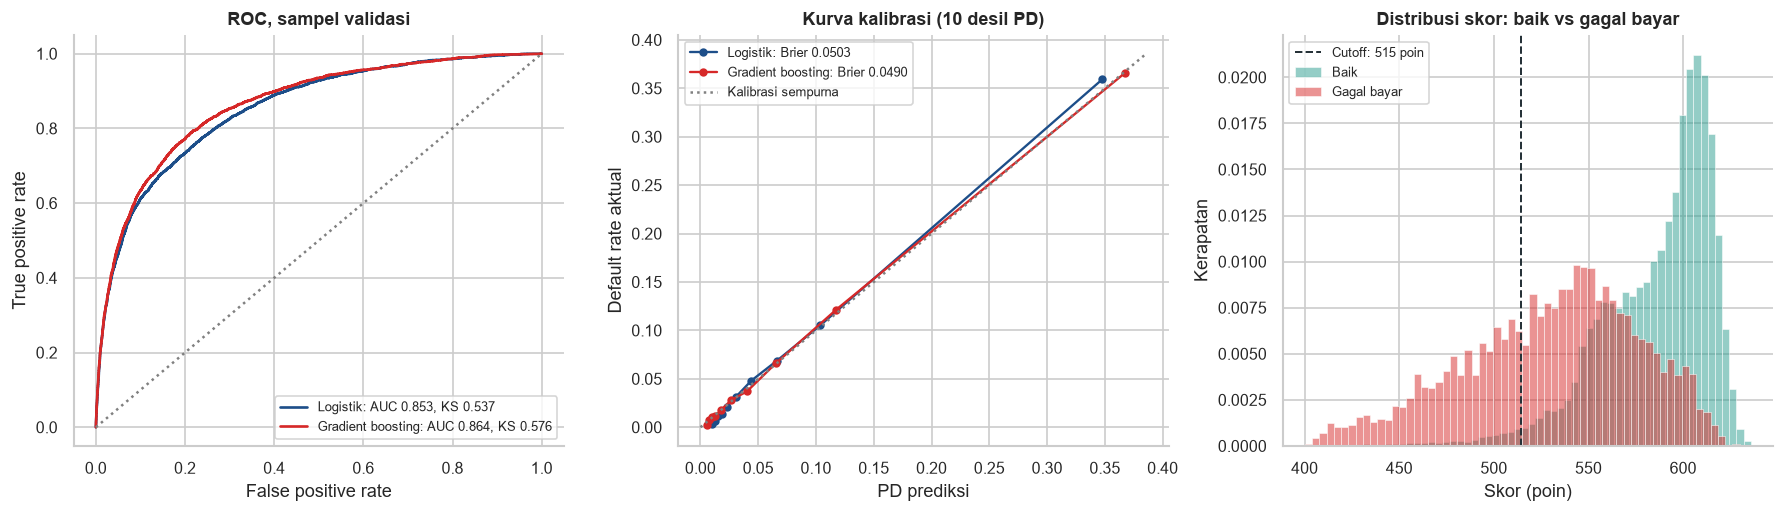

In [7]:
print("Champion (logistik) vs challenger (gradient boosting), sampel validasi:"); display(val)
print("\nKoefisien regresi logistik (fitur terstandardisasi, diurutkan dari pengaruh terbesar):")
display(coef.to_frame("koefisien"))
print("\nDefault rate aktual per desil skor (1 = skor terendah):"); display(band)

fig, ax = plt.subplots(1, 3, figsize=(15, 4.4), dpi=120)
for (k, p), c in zip(p_val.items(), ["#1d4e89", "#d62828"]):
    fpr, tpr, _ = roc_curve(y_val, p)
    ax[0].plot(fpr, tpr, color=c, lw=1.6, label=f"{k}: AUC {val.AUC[k]:.3f}, KS {val.KS[k]:.3f}")
    pt, pp = calibration_curve(y_val, p, n_bins=10, strategy="quantile")
    ax[1].plot(pp, pt, "o-", color=c, ms=4, lw=1.4, label=f"{k}: Brier {val.Brier[k]:.4f}")
ax[0].plot([0, 1], [0, 1], ":", color="grey")
ax[0].set(title="ROC, sampel validasi", xlabel="False positive rate", ylabel="True positive rate")
lim = max(ax[1].get_xlim()[1], ax[1].get_ylim()[1])
ax[1].plot([0, lim], [0, lim], ":", color="grey", label="Kalibrasi sempurna")
ax[1].set(title="Kurva kalibrasi (10 desil PD)", xlabel="PD prediksi", ylabel="Default rate aktual")
for lab, d, c in [("Baik", port[port.default == 0], "#2a9d8f"), ("Gagal bayar", port[port.default == 1], "#d62828")]:
    sns.histplot(d.skor, bins=60, stat="density", color=c, alpha=0.5, edgecolor="white", linewidth=0.3, label=lab, ax=ax[2])
ax[2].axvline(cutoff, color="#263238", ls="--", lw=1.2, label=f"Cutoff: {cutoff:.0f} poin")
ax[2].set(title="Distribusi skor: baik vs gagal bayar", xlabel="Skor (poin)", ylabel="Kerapatan")
for a in ax:
    a.legend(fontsize=8, frameon=True, edgecolor="#cccccc"); a.title.set(fontweight="bold"); sns.despine(ax=a)
plt.tight_layout(); plt.savefig("images/validation.png", bbox_inches="tight"); plt.show()

### 5.3 Cutoff, portfolio loss and stress test

In [8]:
print("Efek cutoff, diukur dengan hasil aktual:"); display(cut.to_frame("nilai"))
print("\nDistribusi kerugian 12 bulan, 10.000 skenario Vasicek (% portofolio):"); display(m * 100)
print("\nStress test (rugi dalam % portofolio):")
display(stres.assign(**{c: stres[c] * 100 for c in ["PD12 rata-rata", "Rugi tanpa cutoff", "Rugi dengan cutoff"]}))
print("\nKRI:"); display(kri)

Efek cutoff, diukur dengan hasil aktual:


,nilai
Approval rate,0.953
"Bad rate aktual, semua",0.067
"Bad rate aktual, lolos",0.046
"Bad rate aktual, ditolak",0.487
EL tanpa cutoff,0.017
EL dengan cutoff,0.010



Distribusi kerugian 12 bulan, 10.000 skenario Vasicek (% portofolio):


,Tanpa cutoff,Dengan cutoff
EL,1.689,0.996
Std,1.226,0.962
VaR 99,6.105,4.684
CVaR 99,7.451,5.931
UL = VaR − EL,4.415,3.689



Stress test (rugi dalam % portofolio):


,Z,1 dari N tahun,PD12 rata-rata,Rugi tanpa cutoff,Rugi dengan cutoff,Rugi / EL
Median,0,2.000,3.031,1.364,0.698,0.807
Ringan,-1,6.303,5.942,2.674,1.695,1.583
Berat,-2,43.956,10.974,4.938,3.634,2.924
Ekstrem,-3,740.797,18.900,8.505,6.907,5.035



KRI:


,nilai,hijau,kuning,arah,status
KRI,,,,,
AUC model PD,0.853,0.750,0.700,-1,HIJAU
PSI skor dev → val,0.000,0.100,0.250,1,HIJAU
VaR 99 (% portofolio),0.061,0.040,0.060,1,MERAH


### 5.4 Dashboard

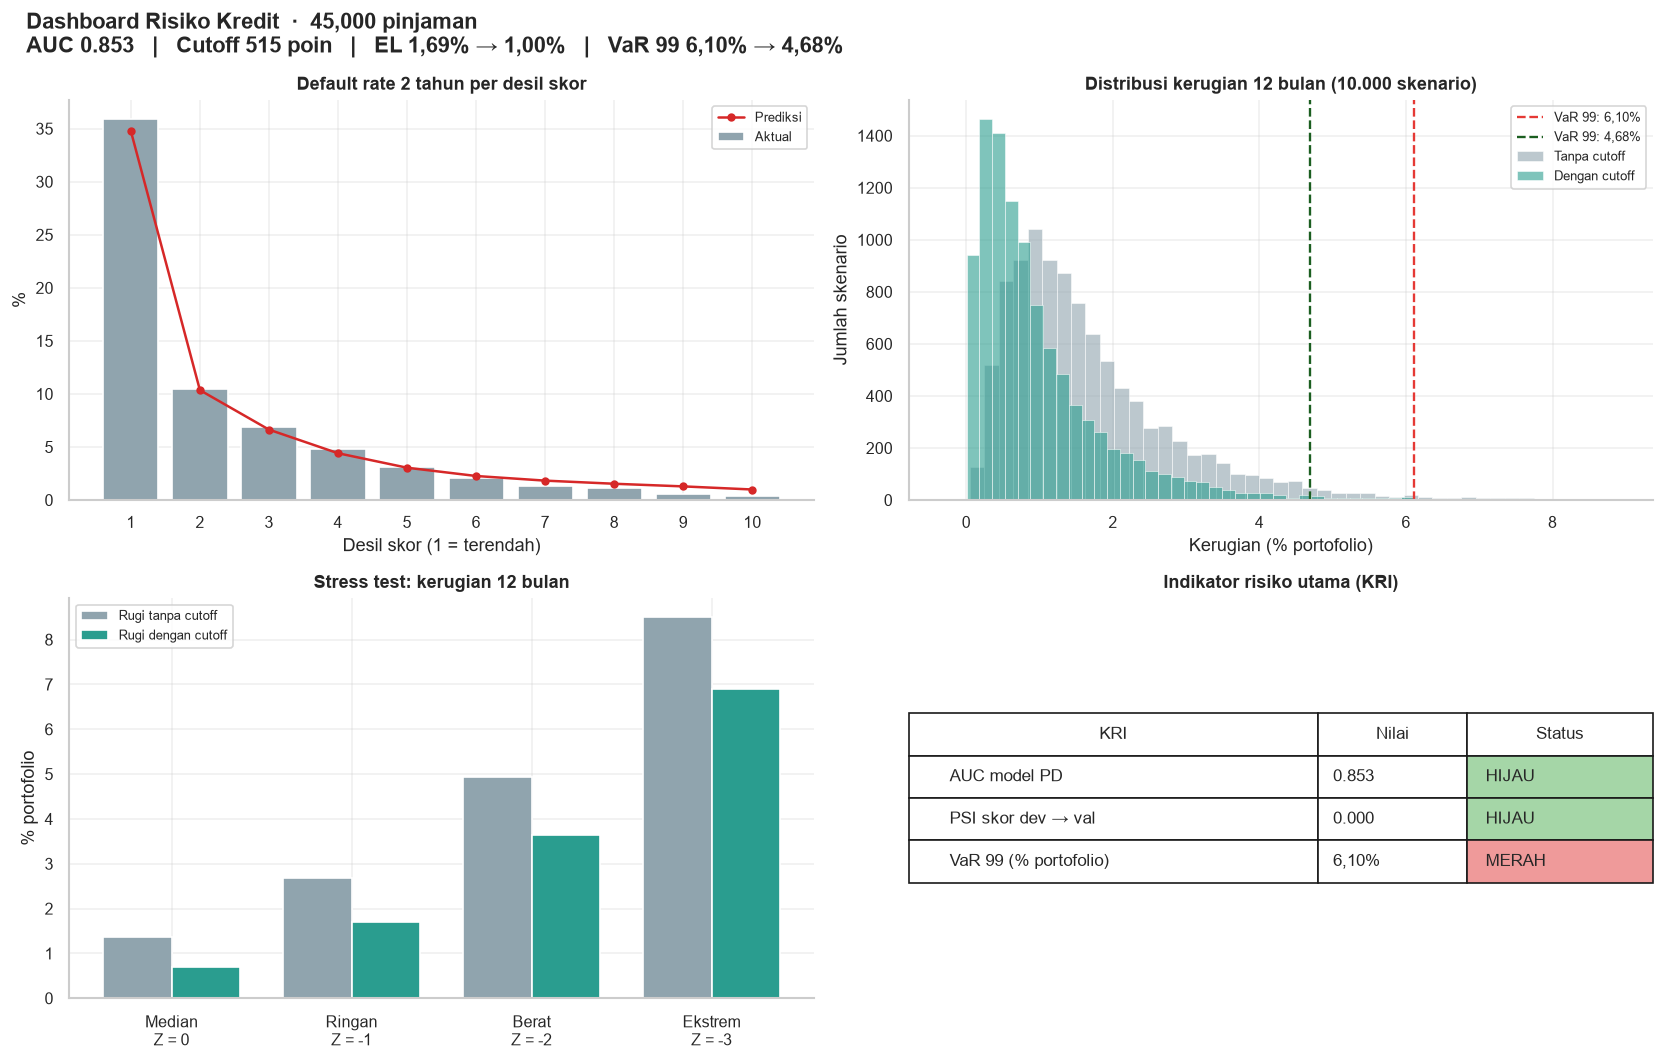

In [9]:
fig, ax = plt.subplot_mosaic([["band", "loss"], ["stres", "kri"]], figsize=(14, 9), dpi=120)
fig.suptitle(f"Dashboard Risiko Kredit  ·  {len(port):,} pinjaman\n"
             f"AUC {val.AUC['Logistik']:.3f}   |   Cutoff {cutoff:.0f} poin   |   "
             f"EL {pct(mt['EL'])} → {pct(mc['EL'])}   |   VaR 99 {pct(mt['VaR 99'])} → {pct(mc['VaR 99'])}",
             fontsize=13, fontweight="bold", x=0.02, ha="left")

# (a) Default rate per desil skor
ax["band"].bar(band.index.astype(str), band.default_aktual * 100, color="#90a4ae", label="Aktual")
ax["band"].plot(band.index.astype(str), band.pd_prediksi * 100, "o-", color="#d62828", ms=4, label="Prediksi")
ax["band"].set(title="Default rate 2 tahun per desil skor", xlabel="Desil skor (1 = terendah)", ylabel="%")
ax["band"].legend(fontsize=8, frameon=True, edgecolor="#cccccc")

# (b) Distribusi kerugian, tanpa vs dengan cutoff
for c, lab, col in [(L, "Tanpa cutoff", "#90a4ae"), (L_cut, "Dengan cutoff", "#2a9d8f")]:
    sns.histplot(c * 100, bins=80, color=col, alpha=0.6, edgecolor="white", linewidth=0.3, label=lab, ax=ax["loss"])
for c, col in [(mt, "#e53935"), (mc, "#1b5e20")]:
    ax["loss"].axvline(c["VaR 99"] * 100, color=col, ls="--", lw=1.4, label=f"VaR 99: {pct(c['VaR 99'])}")
ax["loss"].set(title="Distribusi kerugian 12 bulan (10.000 skenario)", xlabel="Kerugian (% portofolio)",
               ylabel="Jumlah skenario", xlim=(None, np.quantile(L, 0.9995) * 100))
ax["loss"].legend(fontsize=8, frameon=True, edgecolor="#cccccc")

# (c) Stress test
x = np.arange(len(stres))
for i, (c, col) in enumerate([("Rugi tanpa cutoff", "#90a4ae"), ("Rugi dengan cutoff", "#2a9d8f")]):
    ax["stres"].bar(x + (i - 0.5) * 0.38, stres[c] * 100, 0.38, color=col, label=c)
ax["stres"].set_xticks(x, [f"{k}\nZ = {z}" for k, z in zip(stres.index, stres.Z)])
ax["stres"].set(title="Stress test: kerugian 12 bulan", ylabel="% portofolio")
ax["stres"].legend(fontsize=8, frameon=True, edgecolor="#cccccc")

# (d) Tabel KRI berwarna
t = ax["kri"].table(cellText=[[k, f"{r.nilai:.3f}" if "VaR" not in k else pct(r.nilai), r.status] for k, r in kri.iterrows()],
                    colLabels=["KRI", "Nilai", "Status"], cellLoc="left", colWidths=[0.55, 0.2, 0.25], loc="center")
t.auto_set_font_size(False); t.set_fontsize(10); t.scale(1, 2)
for i, r in enumerate(kri.itertuples(), start=1):
    t[i, 2].set_facecolor(warna[r.status])
ax["kri"].axis("off"); ax["kri"].set_title("Indikator risiko utama (KRI)")

for a in ax.values():
    a.title.set(fontsize=11, fontweight="bold")
    if a is not ax["kri"]:
        a.grid(alpha=0.3); sns.despine(ax=a)
plt.tight_layout(); plt.savefig("images/dashboard.png", bbox_inches="tight"); plt.show()

## Limitations and next steps

- LGD, EAD and correlation are single assumed values. With real loan data they would be estimated: LGD from recoveries, EAD from limits and drawdowns.
- The Vasicek model uses one factor and a large-portfolio approximation, so concentration in large borrowers is not captured.
- Stress scenarios are set directly on Z. A bank would link Z to macro variables (interest rate, exchange rate, GDP) by regressing its own default history on them.
- **Next steps:** PSAK 71 / IFRS 9 staging with lifetime ECL needs days-past-due data, which this dataset does not have. To apply the model to Indonesian micro and MSME lending, the portfolio could be split by segment weights from a bank's published report, with segment-specific LGD.